In [50]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

df = pd.read_csv("./data/bdc_37_fixed_broadband_served_unserved_J26_24oct2026.csv")
county_geoids_df = pd.read_csv("./data/ncstate_county_geoids.csv")

In [51]:
df = df.astype({"location_id": str,"block_geoid": str, "any_dl100_ul20": bool, "wired_dl100_ul20": bool, "terrestrial_dl100_ul20": bool})

In [52]:
df["County GEOID"] = df["block_geoid"].str[2:5]
df["Census Tract GEOID"] = df["block_geoid"].str[:11]

In [53]:
clean_df = df[["block_geoid","County GEOID", "Census Tract GEOID", "any_dl100_ul20", "wired_dl100_ul20", "terrestrial_dl100_ul20"]]

In [54]:
clean_df.head()

,block_geoid,County GEOID,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,371719303011000,171,37171930301,True,False,True
1,371899208002015,189,37189920800,True,True,True
2,371899209003025,189,37189920900,True,True,True
3,371899207022041,189,37189920702,True,True,True
4,371899202001018,189,37189920200,True,True,True


In [55]:
county_geoids_df = county_geoids_df.astype({"FIPS Code": str})
county_geoids_df["FIPS Code"] = county_geoids_df["FIPS Code"].str[2:]
county_geoids_df["County"] = county_geoids_df["County"].str.replace(" County", "").str.strip()
county_geoids_df = county_geoids_df.drop(columns="Tracts")
county_geoids_df.head()

,County,FIPS Code
0,Alamance,001
1,Alexander,003
2,Alleghany,005
3,Anson,007
4,Ashe,009


In [56]:
merged_df = pd.merge(clean_df, county_geoids_df[["County", "FIPS Code"]], left_on="County GEOID", right_on="FIPS Code", how="left")
county_col = merged_df.pop("County")
merged_df = merged_df.drop(columns=["FIPS Code"])
merged_df.insert(1, "County", county_col)
merged_df.head()

,block_geoid,County,County GEOID,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,371719303011000,Surry,171,37171930301,True,False,True
1,371899208002015,Watauga,189,37189920800,True,True,True
2,371899209003025,Watauga,189,37189920900,True,True,True
3,371899207022041,Watauga,189,37189920702,True,True,True
4,371899202001018,Watauga,189,37189920200,True,True,True


In [57]:
merged_df["no_terra_service"] = merged_df["terrestrial_dl100_ul20"] == False

threshold = 15

In [58]:
by_county = merged_df.groupby("County")["no_terra_service"].agg(["size","sum","mean"])
by_county = by_county.sort_values(by="mean", ascending=False)
by_county["% Without Coverage"] = round(by_county["mean"] * 100,2)
by_county = by_county.rename(columns={"size": "Total Locations", "sum": "No Terrestrial Service"})
by_county = by_county[by_county["Total Locations"] >= 100]
by_county = by_county[by_county["% Without Coverage"] >= 15]
by_county = by_county.drop(columns="mean")
by_county.head()

,Total Locations,No Terrestrial Service,% Without Coverage
County,,,
Graham,5507,2401,43.60
Swain,10399,4292,41.27
Clay,8106,2646,32.64
Jackson,25809,7274,28.18
Hyde,3824,1076,28.14


In [59]:
by_tract = merged_df.groupby(["County", "Census Tract GEOID"], as_index=False)["no_terra_service"].agg(["size","sum","mean"])
by_tract = by_tract.sort_values(by="mean", ascending=False)
by_tract["% Without Coverage"] = round(by_tract["mean"] * 100,2)
by_tract = by_tract.rename(columns={"size": "Total Locations", "sum": "No Terrestrial Service"})
by_tract = by_tract.drop(columns="mean")
by_tract = by_tract[by_tract["Total Locations"] >= 100]
by_tract = by_tract[by_tract["% Without Coverage"] >= threshold]
print(len(by_tract))
by_tract.head()

120


,County,Census Tract GEOID,Total Locations,No Terrestrial Service,% Without Coverage
1241,Jackson,37099950800,2987,2234,74.79
1240,Jackson,37099950700,1911,1427,74.67
2237,Swain,37173960301,2807,1995,71.07
923,Graham,37075920100,2057,1460,70.98
403,Clay,37043950102,1973,1162,58.90


In [60]:
by_county.to_excel(f"./results/PercentWithoutCoveragebyCountywithThreshold{threshold}.xlsx", index=True)
by_tract.to_excel(f"./results/PercentWithoutCoveragebyTractwithThreshold{threshold}.xlsx", index=True)

In [61]:
shape_df = gpd.read_file("data/tl_2020_37_tract.zip").to_crs(32119)
shape_df.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,37,141,920300,37141920300,9203,Census Tract 9203,G5020,S,236115472,605423,+34.6713171,-078.0020072,"POLYGON ((686896.998 103394.168, 687069.83 103..."
1,37,141,990100,37141990100,9901,Census Tract 9901,G5020,S,0,133298393,+34.3492469,-077.6031267,"POLYGON ((727968.698 60800.547, 727993.265 608..."
2,37,071,031600,37071031600,316,Census Tract 316,G5020,S,22744042,66304,+35.2681382,-081.2849294,"POLYGON ((398030.831 170385.243, 398034.506 17..."
3,37,071,031800,37071031800,318,Census Tract 318,G5020,S,6071060,8149,+35.2623339,-081.2292201,"POLYGON ((404259.886 170518.838, 404382.904 17..."
4,37,155,961801,37155961801,9618.01,Census Tract 9618.01,G5020,S,103973789,0,+34.6244596,-079.2476138,"POLYGON ((581155.624 94311.87, 581164.57 94327..."


In [62]:
map = pd.merge(shape_df, by_tract, left_on="GEOID", right_on="Census Tract GEOID", how="left")
map.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 2672 entries, 0 to 2671
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   STATEFP                 2672 non-null   str     
 1   COUNTYFP                2672 non-null   str     
 2   TRACTCE                 2672 non-null   str     
 3   GEOID                   2672 non-null   str     
 4   NAME                    2672 non-null   str     
 5   NAMELSAD                2672 non-null   str     
 6   MTFCC                   2672 non-null   str     
 7   FUNCSTAT                2672 non-null   str     
 8   ALAND                   2672 non-null   int64   
 9   AWATER                  2672 non-null   int64   
 10  INTPTLAT                2672 non-null   str     
 11  INTPTLON                2672 non-null   str     
 12  geometry                2672 non-null   geometry
 13  County                  120 non-null    str     
 14  Census Tract GEO

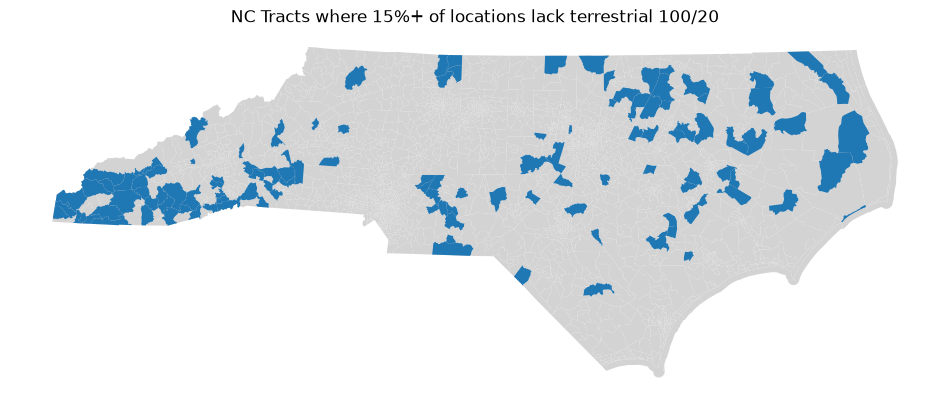

In [63]:
fig, ax = plt.subplots(figsize=(12,6))
map.plot(ax=ax, color="lightgray")

flagged = map[map["% Without Coverage"].notna()]
flagged.plot(ax=ax, color="tab:blue")

ax.set_axis_off()
ax.set_title(f"NC Tracts where {threshold}%+ of locations lack terrestrial 100/20")

fig.savefig(f"results/flagged_tracts_{threshold}pct.png", dpi=150, bbox_inches="tight")

In [ ]:
flagged_cleaned = flagged[["GEOID", "geometry"]]
flagged_cleaned = flagged_cleaned.reset_index(drop=True)

flagged_pairs = gpd.sjoin(flagged_cleaned, flagged_cleaned, predicate="touches")

In [76]:
graph = nx.Graph()

pairs = zip(flagged_pairs["GEOID_left"], flagged_pairs["GEOID_right"])

graph.add_nodes_from(flagged_cleaned["GEOID"])
graph.add_edges_from(pairs)

groups = nx.connected_components(graph)

cluster = {}
for index, group in enumerate(groups, start=1):
    for geoid in group:
        cluster[geoid] = index

flagged["Cluster"] = flagged["GEOID"].map(cluster)

flagged.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,County,Census Tract GEOID,Total Locations,No Terrestrial Service,% Without Coverage,Cluster
17,37,191,000103,37191000103,1.03,Census Tract 1.03,G5020,S,77782716,156895,+35.5488808,-078.0357325,"POLYGON ((690777.911 195652.089, 690828.574 19...",Wayne,37191000103,1283.0,198.0,15.43,1
48,37,015,960100,37015960100,9601,Census Tract 9601,G5020,S,422961809,43116827,+36.1259234,-076.8298463,"POLYGON ((792466.447 263662.602, 792506.214 26...",Bertie,37015960100,3088.0,824.0,26.68,2
50,37,169,070200,37169070200,702,Census Tract 702,G5020,S,193914444,1075423,+36.4620598,-080.2451130,"POLYGON ((490631.61 293495.454, 490633.699 293...",Stokes,37169070200,1988.0,579.0,29.12,3
52,37,169,070600,37169070600,706,Census Tract 706,G5020,S,135971102,1630283,+36.3254971,-080.2035739,"POLYGON ((492563.547 288294.092, 492566.019 28...",Stokes,37169070600,2502.0,444.0,17.75,3
71,37,125,950304,37125950304,9503.04,Census Tract 9503.04,G5020,S,225344221,1523744,+35.3162841,-079.6281541,"POLYGON ((543579.196 178799.986, 543601.716 17...",Moore,37125950304,1586.0,291.0,18.35,4


In [99]:
flagged_clusters = flagged.groupby(["Cluster"], as_index=False).agg({"Total Locations": "sum", "No Terrestrial Service": "sum","Census Tract GEOID": "count", "County": lambda x: list(x.unique())})
flagged_clusters["% Without Coverage"] = round((flagged_clusters["No Terrestrial Service"] / flagged_clusters["Total Locations"]) * 100, 2)
flagged_clusters = flagged_clusters.sort_values(["No Terrestrial Service"], ascending=False)
flagged_clusters.rename(columns={"Census Tract GEOID": "# of Tracts"})
flagged_clusters.head()

,Cluster,Total Locations,No Terrestrial Service,Census Tract GEOID,County,% Without Coverage
9,10,66793.0,22587.0,28,"[Cherokee, Graham, Jackson, Swain, Macon, Clay...",33.82
8,9,15808.0,3936.0,8,"[Henderson, Polk, Transylvania]",24.90
20,21,14403.0,3341.0,9,"[Nash, Franklin, Halifax, Warren]",23.20
29,30,13245.0,2949.0,8,"[Anson, Stanly, Cabarrus]",22.27
15,16,12429.0,2709.0,9,"[Buncombe, McDowell, Rutherford]",21.80
